## Установка зависимостей


In [1]:
# Не переустанавливаем PyTorch/CUDA, предоставленные Kaggle.
%pip install -q -U "openai>=1.68,<3" "pydantic>=2,<3" "diffusers==0.39.0" "transformers==4.57.6" "accelerate==1.15.0" safetensors pillow "psutil>=5.9,<8"
print("Run → Restart & clear cell outputs. Затем запускайте с THEME через Run current and after.")


Note: you may need to restart the kernel to use updated packages.
Run → Restart & clear cell outputs. Затем запускайте с THEME через Run current and after.


## Настройки


In [2]:
THEME = "Вид с высокой изогнутой террасы на гигантский мегаполис будущего над водой. На переднем плане — плавные линии балконов и крошечные силуэты людей. Вдали поднимаются колоссальные башни со шпилями и спиральными внешними каркасами. Между зданиями проходят многоуровневые мосты и каналы. Тысячи золотых огней отражаются в тёмной воде. Холодные сине-серые сумерки, низкие облака, влажные поверхности. Монументальная архитектура, кинематографичный реализм и ощущение невероятного масштаба."
MAX_ROUNDS = 3
SEED = 20261011
STEPS = 30
GUIDANCE_SCALE = 5.5
WIDTH = HEIGHT = 1024
CRITIC_MODEL = "qwen3.6-35b-a3b"
YANDEX_TEXT_MODEL = "yandexgpt/latest"
SDXL_MODEL = "stabilityai/stable-diffusion-xl-base-1.0"
YANDEX_IMAGE_MODEL = "aliceai-image-art-3.0"  # art://folder/model, без /latest
API_ATTEMPTS = 4
JSON_ATTEMPTS = 3
RESUME_DIR = ""
RUN_PIPELINE = True


## Клиенты и сохранение состояния


In [3]:
# Инфраструктура: секреты, контрольные точки и память. API вызываются только при запуске.
import base64, ctypes, gc, hashlib, importlib.metadata, json, platform, random, re, shutil, time, uuid
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path
from typing import Literal
import psutil
import torch
from PIL import Image
from IPython.display import display, Markdown, FileLink
from pydantic import BaseModel, ConfigDict, Field, ValidationError, create_model
from openai import OpenAI
from diffusers import StableDiffusionXLPipeline, AutoencoderKL
from kaggle_secrets import UserSecretsClient

BRANCHES = ("yandex", "sdxl")
YANDEX_PROMPT_LIMIT = 500
ARTISTS = {"yandex": "Yandex ART", "sdxl": "SDXL Base 1.0"}
CONFIG = dict(schema_version=8, theme=THEME, max_rounds=MAX_ROUNDS, seed=SEED,
              steps=STEPS, guidance_scale=GUIDANCE_SCALE, width=WIDTH, height=HEIGHT,
              critic_model=CRITIC_MODEL, yandex_text_model=YANDEX_TEXT_MODEL,
              sdxl_model=SDXL_MODEL, yandex_image_model=YANDEX_IMAGE_MODEL,
              revision_policy="text_feedback_and_exchange", memory_mode="model_cpu_offload")
# Повторное выполнение определений не создаёт вторую копию весов и новый эксперимент.
MODEL_CACHE = globals().get("MODEL_CACHE", {})
SESSION = globals().get("SESSION")

def utc_now():
    return datetime.now(timezone.utc).isoformat()

def atomic_json(path, value):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(path)

def checkpoint():
    atomic_json(RUN_DIR / "state.json", state)

def log_event(kind, **data):
    with (RUN_DIR / "events.jsonl").open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(dict(time=utc_now(), kind=kind, **data), ensure_ascii=False) + "\n")

def release_memory():
    gc.collect()
    if platform.system() == "Linux":
        try:
            ctypes.CDLL(None).malloc_trim(ctypes.c_size_t(0))
        except (AttributeError, OSError):
            pass
    # empty_cache не освобождает живые веса; между раундами он здесь не нужен.

def memory_snapshot(label):
    gib = 1024**3
    values = dict(label=label, rss_gib=round(psutil.Process().memory_info().rss/gib, 3),
                  gpu_allocated_gib=round(torch.cuda.memory_allocated(0)/gib, 3),
                  gpu_reserved_gib=round(torch.cuda.memory_reserved(0)/gib, 3))
    try:
        stats = dict(line.split() for line in Path('/sys/fs/cgroup/memory.stat').read_text().splitlines())
        values.update(container_anon_gib=round(int(stats['anon'])/gib, 3),
                      container_file_cache_gib=round(int(stats['file'])/gib, 3))
    except (OSError, KeyError, ValueError):
        pass
    log_event("memory", **values)
    print(f"Память: RAM процесса {values['rss_gib']:.2f} GiB; GPU живые/кеш {values['gpu_allocated_gib']:.2f}/{values['gpu_reserved_gib']:.2f} GiB")

def start_session():
    global SESSION, RUN_DIR, state, yandex, TEXT_URI, CRITIC_URI, IMAGE_URI
    if not THEME.strip() or not 1 <= MAX_ROUNDS <= 10:
        raise ValueError("Нужны THEME и MAX_ROUNDS от 1 до 10.")
    if (WIDTH, HEIGHT) != (1024, 1024) or STEPS < 20 or not 1 < GUIDANCE_SCALE <= 12:
        raise ValueError("Используйте 1024×1024, STEPS ≥ 20 и 1 < GUIDANCE_SCALE ≤ 12.")
    if not torch.cuda.is_available():
        raise RuntimeError("Включите GPU и Internet в настройках Kaggle.")
    if SESSION:
        if SESSION['config'] != CONFIG or SESSION['resume_dir'] != RESUME_DIR:
            raise ValueError("Настройки изменились. Перезапустите kernel и начните новую сессию.")
        return
    secrets = UserSecretsClient()
    def secret(name):
        try:
            value = secrets.get_secret(name).strip()
        except Exception:
            raise RuntimeError(f"Добавьте Secret {name} и разрешите notebook доступ.") from None
        if not value:
            raise RuntimeError(f"Secret {name} пуст.")
        return value
    folder = secret("folder_id")
    yandex = OpenAI(api_key=secret("api_key"), project=folder,
                    base_url="https://ai.api.cloud.yandex.net/v1", timeout=180, max_retries=0)
    TEXT_URI = f"gpt://{folder}/{YANDEX_TEXT_MODEL}"
    CRITIC_URI = f"gpt://{folder}/{CRITIC_MODEL}"
    IMAGE_URI = f"art://{folder}/{YANDEX_IMAGE_MODEL}"
    if RESUME_DIR:
        RUN_DIR = Path(RESUME_DIR).expanduser().resolve()
        state = json.loads((RUN_DIR / 'state.json').read_text(encoding='utf-8'))
        saved_config = state['config']
        if {k:v for k,v in saved_config.items() if k!='memory_mode'} != {k:v for k,v in CONFIG.items() if k!='memory_mode'}:
            raise ValueError("RESUME_DIR относится к другой теме/настройкам/версии. Начните новый запуск.")
        if saved_config != CONFIG:
            log_event('runtime_policy_changed',old_memory_mode=saved_config.get('memory_mode'),
                      new_memory_mode=CONFIG['memory_mode'])
            state['config'] = CONFIG.copy()
            checkpoint()
    else:
        run_id = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:6]
        RUN_DIR = Path('/kaggle/working/artist_runs') / run_id
        RUN_DIR.mkdir(parents=True, exist_ok=False)
        state = dict(run_id=run_id, created_at=utc_now(), config=CONFIG, brief=None,
                     rounds=[], complete=False)
        packages = {p: importlib.metadata.version(p) for p in
                    ('torch','diffusers','transformers','accelerate','openai','pydantic','pillow')}
        atomic_json(RUN_DIR/'environment.json', dict(python=platform.python_version(), packages=packages,
                    cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0), gpu_id=0,
                    vae_dtype='float32', generation_order='sequential', one_sdxl_pipeline=True,
                    memory_mode=CONFIG['memory_mode']))
        checkpoint()
    SESSION = dict(config=CONFIG.copy(), resume_dir=RESUME_DIR)
    print("Папка запуска:", RUN_DIR)

def verified_path(metadata):
    path = (RUN_DIR / metadata['path']).resolve()
    if not path.is_relative_to(RUN_DIR.resolve()):
        raise ValueError("Путь изображения выходит за пределы запуска.")
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != metadata['sha256']:
        raise RuntimeError(f"Изображение отсутствует или изменено: {path}")
    return path


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


## Сообщения и API


In [4]:
# Короткие контракты сообщений. Никаких баллов и заявлений об успехе до просмотра картинки.
class Message(BaseModel):
    model_config = ConfigDict(extra='forbid')

class Requirement(Message):
    id: str = Field(min_length=1, max_length=40)
    description: str = Field(min_length=5, max_length=240)
    source_quote: str = Field(min_length=2)

class Brief(Message):
    title: str = Field(min_length=3, max_length=100)
    scene: str = Field(min_length=20, description="Полный сюжет одной картины, 1–3 коротких предложения.")
    composition: str = Field(min_length=20, description="Расположение объектов в одной сцене, без разделения между художниками.")
    style: str = Field(min_length=5, description="Стиль и настроение из исходной темы, одна короткая фраза.")
    requirements: list[Requirement] = Field(min_length=1, max_length=16)

class Plan(Message):
    positive_prompt: str = Field(min_length=10)
    negative_prompt: str
    changes: list[str] = Field(min_length=1, max_length=3)
    borrowed: bool
    borrow_reason: str = Field(min_length=5)


class Check(Message):
    requirement_id: str
    status: Literal['pass', 'fail', 'uncertain']
    evidence: str = Field(min_length=5, max_length=300)

class Problem(Message):
    severity: Literal['major', 'minor']
    observation: str = Field(min_length=5, max_length=300)

class Review(Message):
    branch: Literal['yandex', 'sdxl']
    checks: list[Check]
    strengths: list[str] = Field(max_length=4)
    problems: list[Problem] = Field(max_length=4)
    change_result: Literal['initial', 'realized', 'partially_realized', 'not_realized', 'uncertain']
    change_evidence: str = Field(min_length=5, max_length=300)
    borrow_result: Literal['none', 'realized', 'not_realized', 'uncertain']
    borrow_evidence: str = Field(min_length=5, max_length=300)
    next_change: str = Field(min_length=5, max_length=300)

class BorrowHint(Message):
    source: Literal['yandex', 'sdxl']
    target: Literal['yandex', 'sdxl']
    observation: str = Field(min_length=5, max_length=300)
    adaptation: str = Field(min_length=5, max_length=300)
    success_check: str = Field(min_length=5, max_length=300)

class RoundReview(Message):
    reviews: list[Review] = Field(min_length=2, max_length=2)
    borrow_hints: list[BorrowHint] = Field(max_length=2)


def error_status(exc):
    try:
        return int(getattr(exc, 'status_code', None) or getattr(exc, 'code', None))
    except (ValueError, TypeError):
        return None

def with_retry(operation, label):
    for attempt in range(API_ATTEMPTS):
        try:
            return operation()
        except Exception as exc:
            status = error_status(exc)
            transient = status in {408,429,500,502,503,504} or type(exc).__name__ in {
                'APIConnectionError','APITimeoutError','ConnectError','ReadTimeout','TimeoutException'}
            log_event('api_error', label=label, attempt=attempt+1,
                      status=status, error_type=type(exc).__name__)
            if not transient or attempt+1 == API_ATTEMPTS:
                raise
            delay = min(30, 2**(attempt+1)) + random.random()
            print(f"{label}: временная ошибка {status}, повтор через {delay:.1f} с")
            time.sleep(delay)

def parse_json(raw):
    text = (raw or '').strip()
    if text.startswith('```') and text.endswith('```'):
        text = '\n'.join(text.splitlines()[1:-1])
    return json.loads(text)

def agent_call(role, instruction, payload, schema, validate, pictures=None):
    # SDK retries выключены: здесь один явный ограниченный цикл сетевых повторов.
    request = json.dumps(payload, ensure_ascii=False)
    for attempt in range(JSON_ATTEMPTS):
        if pictures is None:
            response = with_retry(lambda: yandex.responses.create(model=TEXT_URI,
                input=[{'role':'system','content':instruction},
                       {'role':'user','content':request}], temperature=0.2, max_output_tokens=3000,
                text={'format': {'type':'json_schema','name':schema.__name__,
                                 'schema':schema.model_json_schema(),'strict':True}}), role)
            raw = response.output_text
            usage = getattr(response,'usage',None)
        else:
            response = with_retry(lambda: yandex.chat.completions.create(model=CRITIC_URI,
                messages=[{'role':'system','content':instruction},
                          {'role':'user','content':[{'type':'text','text':request},*pictures]}],
                temperature=0.2,max_tokens=6000,
                response_format={'type':'json_schema','json_schema':{'name':schema.__name__,
                    'schema':schema.model_json_schema(),'strict':True}}),role)
            if not response.choices:
                raise RuntimeError(f'{role}: Qwen вернул пустой список choices.')
            raw = response.choices[0].message.content
            usage = getattr(response,'usage',None)
        log_event('agent_message',role=role,model=CRITIC_MODEL if pictures is not None else YANDEX_TEXT_MODEL,
                  instructions=instruction,
                  request=request, raw_response=raw,
                  usage=usage.model_dump(mode='json') if usage else None)
        if pictures is None and getattr(response,'status',None) == 'incomplete':
            raise RuntimeError(f"{role}: ответ обрезан; проверьте лимит и events.jsonl.")
        if pictures is not None and response.choices[0].finish_reason=='length':
            raise RuntimeError(f'{role}: ответ Qwen обрезан. Проверьте max_tokens и events.jsonl.')
        if pictures is not None and response.choices[0].finish_reason=='content_filter':
            raise RuntimeError(f'{role}: Qwen отклонил запрос фильтром содержимого.')
        try:
            result = schema.model_validate(parse_json(raw))
            validate(result)
            return result.model_dump(mode='json')
        except (ValueError, ValidationError) as exc:
            errors = exc.errors(include_url=False, include_input=False) if isinstance(exc, ValidationError) else str(exc)
            log_event('invalid_agent_message',role=role,errors=errors)
            if attempt+1 == JSON_ATTEMPTS:
                raise ValueError(f"{role}: JSON не прошёл проверку. Детали в events.jsonl.") from exc
            request = json.dumps(dict(original_request=payload, previous_answer=raw,
                validation_error=errors, task='Исправь объект, сохрани требования и область своей роли.'), ensure_ascii=False)


## Генерация изображений


In [5]:
# Художники: один text2img-пайплайн SDXL, по одному изображению каждой ветки за раунд.
def load_sdxl():
    if MODEL_CACHE:
        if MODEL_CACHE['model'] != SDXL_MODEL or MODEL_CACHE.get('memory_mode') != CONFIG['memory_mode']:
            raise ValueError('Модель или режим памяти изменены: перезапустите kernel.')
        return MODEL_CACHE['base']
    print('Загрузка SDXL: поэтапный перенос CPU → cuda:0…')
    vae = AutoencoderKL.from_pretrained(SDXL_MODEL, subfolder='vae', variant='fp16',
        torch_dtype=torch.float32, use_safetensors=True, low_cpu_mem_usage=True)
    base = StableDiffusionXLPipeline.from_pretrained(SDXL_MODEL, vae=vae, variant='fp16',
        torch_dtype=torch.float16, use_safetensors=True, low_cpu_mem_usage=True, add_watermarker=False)
    base.vae.enable_slicing()
    base.vae.enable_tiling()
    assert base.vae.dtype == torch.float32
    base.enable_model_cpu_offload(gpu_id=0, device='cuda')
    base.set_progress_bar_config(leave=False)
    MODEL_CACHE.update(model=SDXL_MODEL, memory_mode=CONFIG['memory_mode'], base=base)
    release_memory()
    log_event('model_loaded', model=SDXL_MODEL, vae_dtype=str(base.vae.dtype),
              one_pipeline=True, memory_mode=CONFIG['memory_mode'])
    return base

def prompt_tokens(text):
    base = load_sdxl()
    return [dict(tokens=len(t(text, truncation=False)['input_ids']), limit=t.model_max_length)
            for t in (base.tokenizer, base.tokenizer_2)]

def validate_prompt(plan, branch):
    if branch == 'yandex':
        if len(plan.positive_prompt) > YANDEX_PROMPT_LIMIT or plan.negative_prompt:
            raise ValueError(f'Yandex ART: {len(plan.positive_prompt)} символов, максимум {YANDEX_PROMPT_LIMIT}; negative_prompt должен быть пустым.')
    else:
        for field in ('positive_prompt','negative_prompt'):
            counts = prompt_tokens(getattr(plan, field))
            if any(c['tokens'] > c['limit'] for c in counts):
                raise ValueError(f'{field} превышает CLIP: {counts}. Сократи, не потеряв объекты и отношения.')

def scale_latents(pipe, latents, inverse=False):
    mean, std = getattr(pipe.vae.config,'latents_mean',None), getattr(pipe.vae.config,'latents_std',None)
    factor = pipe.vae.config.scaling_factor
    if mean is not None and std is not None:
        mean = torch.tensor(mean, device=latents.device, dtype=latents.dtype).view(1,-1,1,1)
        std = torch.tensor(std, device=latents.device, dtype=latents.dtype).view(1,-1,1,1)
        return latents*std/factor+mean if inverse else (latents-mean)*factor/std
    return latents/factor if inverse else latents*factor

def decode_image(pipe, latents):
    if pipe.vae.dtype != torch.float32:
        raise RuntimeError('VAE должен оставаться FP32.')
    decoded = pipe.vae.decode(scale_latents(pipe, latents.float(), inverse=True), return_dict=False)[0]
    if not torch.isfinite(decoded).all().item():
        raise RuntimeError('VAE вернул NaN/Inf. Изображение не сохранено.')
    return pipe.image_processor.postprocess(decoded, output_type='pil')[0]

def save_image(image, destination, parameters, started):
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix('.tmp.png')
    image.save(temporary, format='PNG')
    temporary.replace(destination)
    result = dict(path=str(destination.relative_to(RUN_DIR)), sha256=hashlib.sha256(destination.read_bytes()).hexdigest(),
                  actual_size=list(image.size), seconds=round(time.monotonic()-started,2), parameters=parameters)
    log_event('image_generated', **result)
    return result

def render_artist(branch, item, number):
    started = time.monotonic()
    destination = RUN_DIR/'rounds'/f'round_{number:02d}'/f'{branch}.png'
    plan = item['plan']
    if branch == 'yandex':
        validate_prompt(Plan.model_validate(plan),branch)
        print(f"  Yandex ART: длина запроса {len(plan['positive_prompt'])}/{YANDEX_PROMPT_LIMIT} символов")
        response = with_retry(lambda: yandex.images.generate(model=IMAGE_URI,
                    prompt=plan['positive_prompt'], size=f'{WIDTH}x{HEIGHT}'), 'Yandex ART')
        if len(response.data or []) != 1 or not response.data[0].b64_json:
            raise RuntimeError('Yandex ART не вернул одно изображение в b64_json.')
        with BytesIO(base64.b64decode(response.data[0].b64_json, validate=True)) as stream, Image.open(stream) as raw:
            image = raw.convert('RGB')
        try:
            if image.size != (WIDTH, HEIGHT):
                raise RuntimeError(f'Неверный размер Yandex ART: {image.size}')
            return save_image(image,destination,dict(model=YANDEX_IMAGE_MODEL,mode='text2img',
                        seed=None,prompt_characters=len(plan['positive_prompt'])),started)
        finally:
            image.close()
    base = load_sdxl()
    seed = SEED + number-1
    parameters = dict(model=SDXL_MODEL, mode='text2img',
                      seed=seed, steps=STEPS, guidance_scale=GUIDANCE_SCALE, vae_dtype='float32',
                      scheduler=type(base.scheduler).__name__, gpu_id=0, memory_mode=CONFIG['memory_mode'],
                      prompt_tokens=prompt_tokens(plan['positive_prompt']),
                      negative_tokens=prompt_tokens(plan['negative_prompt']))
    image = None
    kwargs = latents = None
    try:
        with torch.inference_mode(), torch.cuda.device(0):
            generator = torch.Generator(device='cuda:0').manual_seed(seed)
            kwargs = dict(prompt=plan['positive_prompt'], negative_prompt=plan['negative_prompt'],
                          num_inference_steps=STEPS, guidance_scale=GUIDANCE_SCALE,
                          generator=generator, output_type='latent')
            latents = base(**kwargs,width=WIDTH,height=HEIGHT).images
            base.maybe_free_model_hooks()  # После denoise освобождаем UNet перед VAE.
            image = decode_image(base,latents)
            latents = kwargs = None
        return save_image(image,destination,parameters,started)
    finally:
        latents = kwargs = None
        base.maybe_free_model_hooks()
        if image is not None:
            image.close()


## Агенты и критик


In [11]:
DIRECTOR_SYSTEM = """Ты арт-директор. Опиши одну картину заданной темы, кратко и законченными фразами.
Scene содержит весь сюжет, composition — расположение объектов и направление действия,
style — настроение. Не описывай первую/вторую картину и разных художников.
Requirements — атомарные требования пользователя с точными цитатами, включая отношения
между объектами. Своих требований не добавляй. Верни JSON по схеме, по-русски."""

ENGINEER_SYSTEM = """Ты промпт-инженер одного художника. Каждый раунд — новая картина из текста.
Phase=initial: два промпта по всей исходной теме. Phase=revision: обнови previous_prompt
по own_review и other_review. Исправь важные недостатки, сохрани описания удачных решений,
не теряя обязательные объекты и отношения. Changes — 1–3 конкретных намерения, не заявления об успехе.
Borrow_hint содержит наблюдаемый удачный приём другой картины. Адаптируй его для своей
сцены или обоснованно откажись, если он противоречит теме; соответствующие поля есть в схеме.
Не копируй весь сюжет донора. Не повторяй приём механически, если прошлый перенос не реализован:
измени его формулировку и положение в промпте. Новый запрос должен отличаться от предыдущего.
Yandex: один сжатый русский positive, ориентир 450 символов, максимум 500, negative="".
Сначала обязательные объекты, отношения и изменения; не пересказывай весь разбор. SDXL: английские промпты,
ориентир positive ≤60 CLIP-токенов; negative — релевантные нежелательные признаки.
Верни JSON по схеме, пояснения по-русски."""

CRITIC_SYSTEM = """Ты визуальный критик. Разбери обе подписанные картины current и, начиная
со второго раунда, сравни с previous. Судишь по изображениям, не по намерениям инженеров.
Для каждого требования дай pass/fail/uncertain и наблюдение с местом на картине.
Pass требует исполнения всех частей требования; не добавляй условий, которых нет в теме.
Различай объект внутри другого объекта и объект на фоне; если отношение не видно — uncertain.
Для каждой картины найди strengths и problems. Дай next_change: важные исправления и
разумное развитие удачных решений. Проверь каждую planned_changes: change_result=realized
только если выполнены ВСЕ правки; часть выполнена — partially_realized; ни одна — not_realized.
Изменение посторонней детали не означает исполнения задания. Первый раунд: change_result=initial.
Borrowed=true означает назначенную попытку переноса. Проверь borrow_task.success_check:
результат виден — realized, не появился — not_realized, нельзя уверенно увидеть — uncertain.
Borrow_result=none означает ТОЛЬКО отсутствие задания (borrowed=false), а не неудачный перенос.
Судишь о видимом результате приёма, не о доказательстве его происхождения.
Рассмотри ОБА направления обмена: Yandex → SDXL и SDXL → Yandex. Найди для каждого
получателя один особенно удачный наблюдаемый приём донора, даже если у донора есть другие
недостатки. Borrow_hint: что видно → как адаптировать → как проверить результат.
Если полезного приёма нет, не выдумывай его. В последнем раунде borrow_hints=[].
Не отклоняй картинки, не выбирай победителей, не ставь баллы. Описывай наблюдаемые изменения,
не приписывай их причину переносу: новая генерация также использует другую случайность.
Верни JSON по схеме, пояснения по-русски."""

def restore_source_quote(quote, source):
    if quote in source:
        return quote
    canonical=lambda word:word.casefold().replace('ё','е')
    wanted=[canonical(m.group()) for m in re.finditer(r'\w+',quote)]
    matches=list(re.finditer(r'\w+',source))
    words=[canonical(m.group()) for m in matches]
    if wanted:
        for index in range(len(words)-len(wanted)+1):
            if words[index:index+len(wanted)]==wanted:
                return source[matches[index].start():matches[index+len(wanted)-1].end()]
    raise ValueError(f'Цитата не найдена в THEME: {quote!r}. Выбери исходный фрагмент без перефразирования.')

def create_brief():
    def validate(brief):
        ids = [r.id for r in brief.requirements]
        if len(ids) != len(set(ids)):
            raise ValueError('Требования должны иметь разные id.')
        for requirement in brief.requirements:
            original=requirement.source_quote
            requirement.source_quote=restore_source_quote(original,THEME)
            if requirement.source_quote!=original:
                log_event('source_quote_normalized',requirement_id=requirement.id,
                          model_quote=original,source_quote=requirement.source_quote)
        for text in (brief.scene,brief.composition,brief.style):
            if sum(ch.isalpha() for ch in text) < 5:
                raise ValueError('scene/composition/style должны быть осмысленными фразами, не пунктуацией.')
            if re.search(r'(?i)\b(?:перв\w*|втор\w*|одной|другой)\s+(?:картин\w*|полотн\w*|художник\w*)|\b(?:yandex|яндекс|sdxl)\b', text):
                raise ValueError('Нужна одна общая сцена. Убери разделение на первую/вторую картину и художников.')
    return agent_call('art_director',DIRECTOR_SYSTEM,
                      dict(original_theme=THEME,number_of_paintings=1),Brief,validate)


def unresolved(review):
    return [c['requirement_id'] for c in (review or {}).get('checks',[]) if c['status'] != 'pass']

def branch_feedback(branch):
    previous = next((r for r in reversed(state['rounds']) if r.get('reviewed')),None)
    if previous is None:
        return dict(previous_prompt=None,own_review=None,other_review=None,borrow_hint=None,
                    recent_transfers=[])
    other = next(b for b in BRANCHES if b != branch)
    hint = next((h for h in previous['report']['borrow_hints'] if h['target']==branch),None)
    if hint:
        # Достоинство может быть полезным даже у картины с невыполненными требованиями.
        hint = dict(**hint,source_round=previous['number'],
                    source_path=previous['items'][other]['image']['path'])
    history=[]
    for record in state['rounds']:
        item=record['items'].get(branch,{})
        if item.get('review') and item['plan']['borrowed']:
            history.append(dict(round=record['number'],hint=item['feedback']['borrow_hint'],
                changes=item['plan']['changes'],result=item['review']['borrow_result'],
                evidence=item['review']['borrow_evidence']))
    return dict(previous_prompt=previous['items'][branch]['plan'],
                own_review=previous['items'][branch]['review'],
                other_review=previous['items'][other]['review'],borrow_hint=hint,
                recent_transfers=history[-2:])

def engineer_plan(branch, number, feedback):
    previous = feedback['previous_prompt']
    hint = feedback['borrow_hint']
    limits = dict(language='Russian',max_characters=YANDEX_PROMPT_LIMIT,target_characters=450) if branch=='yandex' else dict(
        language='English',token_limits=[c['limit'] for c in prompt_tokens('')],target_tokens=60)
    fields = dict(positive_prompt=(str,Field(min_length=10,
                      description='Один русский запрос, ориентир 450 символов, максимум 500.')),
                  negative_prompt=(Literal[''],...)) if branch=='yandex' else dict(
                      positive_prompt=(str,Field(min_length=10)),negative_prompt=(str,...))
    if previous:
        fields['changes']=(list[str],Field(min_length=1,max_length=3))
        if hint:
            fields.update(borrowed=(bool,...),borrow_reason=(str,Field(min_length=5)))
    schema=create_model('RevisionPrompt' if previous else 'InitialPrompt',__base__=Message,**fields)
    payload=dict(branch=branch,phase='revision' if previous else 'initial',original_theme=THEME,
                 brief=state['brief'],round=number,generator=limits,**feedback)
    def validate(draft):
        if branch!='yandex':
            validate_prompt(draft,branch)
        if previous:
            normalize=lambda text:' '.join(text.split()).casefold()
            if all(normalize(getattr(draft,key))==normalize(previous[key]) for key in ('positive_prompt','negative_prompt')):
                raise ValueError('Промпты полностью повторены. Примени замечания и адаптацию приёма в новом запросе.')
    draft=agent_call(f'prompt_engineer_{branch}',ENGINEER_SYSTEM,payload,schema,validate)
    plan = Plan.model_validate(dict(positive_prompt=draft['positive_prompt'],
        negative_prompt=draft['negative_prompt'],changes=draft.get('changes',['Создать картину по общей теме']),
        borrowed=draft.get('borrowed',False),
        borrow_reason=draft.get('borrow_reason','Подходящий перенос на этом шаге не предложен.'))).model_dump(mode='json')
    return fit_yandex_plan(plan) if branch=='yandex' else plan

def fit_yandex_plan(plan):
    if len(plan['positive_prompt']) <= YANDEX_PROMPT_LIMIT and not plan['negative_prompt']:
        return plan
    schema = create_model('CompactYandexPrompt',__base__=Message,
        positive_prompt=(str,Field(min_length=10,max_length=YANDEX_PROMPT_LIMIT)),
        negative_prompt=(Literal[''],...))
    draft = agent_call('prompt_engineer_yandex_compact',
        'Сожми запрос для Yandex ART до 450 символов, максимум 500. Сохрани обязательные '
        'объекты, пространственные отношения и запланированные изменения. Убери повторы '
        'и лишние эпитеты. Не добавляй новых деталей. Negative_prompt пуст. Верни JSON.',
        dict(original_theme=THEME,requirements=state['brief']['requirements'],
             positive_prompt=plan['positive_prompt'],negative_prompt=plan['negative_prompt'],
             planned_changes=plan['changes']),schema,lambda result:validate_prompt(result,'yandex'))
    result = dict(plan,positive_prompt=draft['positive_prompt'],negative_prompt=draft['negative_prompt'])
    log_event('prompt_compacted',branch='yandex',before_characters=len(plan['positive_prompt']),
              after_characters=len(result['positive_prompt']))
    return result

def critique_round(record):
    context=dict(original_theme=THEME,requirements=state['brief']['requirements'],
                 round=record['number'],final_round=record['number']==MAX_ROUNDS,tasks={},images=[])
    previous=next((r for r in reversed(state['rounds']) if r.get('reviewed')),None)
    pictures=[]
    for branch in BRANCHES:
        item=record['items'][branch]
        hint=item['feedback']['borrow_hint'] if item['plan']['borrowed'] else None
        context['tasks'][branch]=dict(planned_changes=item['plan']['changes'],
            borrowed=item['plan']['borrowed'],borrow_task=hint)
        pairs=[('current',record['number'],item)]
        if previous:
            pairs.append(('previous',previous['number'],previous['items'][branch]))
        for label,number,selected in pairs:
            path=verified_path(selected['image'])
            caption=f'{branch}: {label}; round={number}'
            context['images'].append(dict(caption=caption,path=selected['image']['path']))
            pictures.extend([{'type':'text','text':caption},
                {'type':'image_url','image_url':{'url':'data:image/png;base64,'+
                    base64.b64encode(path.read_bytes()).decode('ascii')}}])
    def validate(report):
        if len({r.branch for r in report.reviews})!=2:
            raise ValueError('Нужен один review yandex и один sdxl.')
        expected={r['id'] for r in state['brief']['requirements']}
        for review in report.reviews:
            ids=[c.requirement_id for c in review.checks]
            if len(ids)!=len(set(ids)) or set(ids)!=expected:
                raise ValueError('Проверь каждое требование ровно один раз.')
            if (review.change_result=='initial')!=(record['number']==1):
                raise ValueError('change_result=initial только в первом раунде.')
            assigned=record['items'][review.branch]['plan']['borrowed']
            original_status=review.borrow_result
            if assigned and original_status=='none':
                # Назначение известно из плана; отсутствие результата не равно отсутствию задания.
                review.borrow_result='uncertain'
            elif not assigned and original_status!='none':
                review.borrow_result='none'
                review.borrow_evidence='Перенос в этом раунде не назначался; его результат не проверяется.'
            if review.borrow_result!=original_status:
                log_event('critic_transfer_status_normalized',branch=review.branch,
                    round=record['number'],assigned=assigned,model_status=original_status,
                    effective_status=review.borrow_result)
        if record['number']==MAX_ROUNDS and report.borrow_hints:
            raise ValueError('Последний раунд: borrow_hints=[].')
        if len({h.target for h in report.borrow_hints})!=len(report.borrow_hints):
            raise ValueError('Не больше одного предложения каждому получателю.')
        if any(h.source==h.target for h in report.borrow_hints):
            raise ValueError('Перенос возможен только между разными художниками.')
    return agent_call('visual_critic',CRITIC_SYSTEM,context,RoundReview,validate,pictures=pictures)


## Цикл и экспорт


In [7]:
# Оркестратор: новая генерация каждого художника → разбор → обновление промптов.
def export_results():
    final_dir=RUN_DIR/'final'
    final_dir.mkdir(exist_ok=True)
    finals={}
    if state['complete']:
        for branch in BRANCHES:
            final=state['rounds'][-1]['items'][branch]
            source=verified_path(final['image'])
            destination=final_dir/f'{branch}.png'
            shutil.copy2(source,destination)
            finals[branch]=dict(artist=ARTISTS[branch],path=f'final/{branch}.png',
                round=state['rounds'][-1]['number'],plan=final['plan'],assessment=final['review'],
                image_metadata=final['image'],unresolved_requirements=unresolved(final['review']))
    transfers=[]
    for record in state['rounds']:
        for branch,item in record['items'].items():
            if item.get('plan',{}).get('borrowed') and item.get('review'):
                transfers.append(dict(round=record['number'],target=branch,hint=item['feedback']['borrow_hint'],
                    intended_changes=item['plan']['changes'],outcome=item['review']['borrow_result'],
                    evidence=item['review']['borrow_evidence']))
    atomic_json(RUN_DIR/'manifest.json',dict(run_id=state['run_id'],theme=THEME,brief=state['brief'],
               config=CONFIG,complete=state['complete'],finals=finals))
    atomic_json(RUN_DIR/'transfers.json',transfers)
    # Потоковое чтение журнала: большие запросы и ответы не собираются в общий список в RAM.
    with (RUN_DIR/'dialogue.md').open('w',encoding='utf-8') as output:
        output.write(f"# Диалог агентов\n\n{THEME}\n\n")
        log_path=RUN_DIR/'events.jsonl'
        if log_path.exists():
            with log_path.open(encoding='utf-8') as events:
                for line in events:
                    event=json.loads(line)
                    if event['kind']=='agent_message':
                        output.write(f"## {event['role']} · {event['time']}\n\n{event['instructions']}\n\n")
                        output.write('### Вход\n\n```json\n'+event['request']+'\n```\n\n')
                        output.write('### Ответ\n\n```json\n'+(event['raw_response'] or '')+'\n```\n\n')
    archive=shutil.make_archive(str(RUN_DIR),'zip',root_dir=RUN_DIR.parent,base_dir=RUN_DIR.name)
    return Path(archive)

def preview(metadata, label):
    print(label)
    with Image.open(verified_path(metadata)) as image:
        small=image.copy()
    try:
        small.thumbnail((512,512))
        display(small)
    finally:
        small.close()

def run_pipeline():
    if state['complete']:
        print('Этот эксперимент уже завершён. Для новой темы перезапустите kernel.')
        return
    if state['brief'] is None:
        print('Арт-директор формулирует общую сцену…')
        state['brief']=create_brief()
        checkpoint()
    display(Markdown(f"**{state['brief']['title']}**\n\n{state['brief']['scene']}\n\nКомпозиция: {state['brief']['composition']}"))
    for number in range(1,MAX_ROUNDS+1):
        record=next((r for r in state['rounds'] if r['number']==number),None)
        if record and record.get('reviewed'):
            continue
        print(f'\nРаунд {number}/{MAX_ROUNDS}')
        if record is None:
            record=dict(number=number,items={})
            state['rounds'].append(record)
            checkpoint()
        for branch in BRANCHES:
            item=record['items'].get(branch)
            if item is None:
                feedback=branch_feedback(branch)
                item=dict(feedback=feedback)
                record['items'][branch]=item
                checkpoint()
            if 'plan' not in item:
                print(f'  Инженер {ARTISTS[branch]}…')
                item['plan']=engineer_plan(branch,number,item['feedback'])
                checkpoint()
            print(f"  Намерения {branch}: {'; '.join(item['plan']['changes'])}")
            if item['feedback']['borrow_hint']:
                print(f"  Перенос: {item['plan']['borrowed']} — {item['plan']['borrow_reason']}")
            if 'image' not in item:
                if branch=='yandex':
                    item['plan']=fit_yandex_plan(item['plan'])
                    checkpoint()
                item['image']=render_artist(branch,item,number)
                checkpoint()
            preview(item['image'],f"  {ARTISTS[branch]}: раунд {number}")
            release_memory()
        if 'report' not in record:
            print('  Qwen разбирает удачные решения, недостатки и оба направления обмена…')
            record['report']=critique_round(record)
            checkpoint()
        for review in record['report']['reviews']:
            record['items'][review['branch']]['review']=review
        for branch in BRANCHES:
            item=record['items'][branch]
            print(f"  Разбор {ARTISTS[branch]}")
            for strength in item['review']['strengths']:
                print('    Удачно:',strength)
            for problem in item['review']['problems']:
                print('    Проблема:',problem['observation'])
            print('  Результат правки:',item['review']['change_result'],'—',item['review']['change_evidence'])
            for check in item['review']['checks']:
                print(f"    {check['requirement_id']}: {check['status']} — {check['evidence']}")
            if item['plan']['borrowed']:
                print('  Проверка переноса:',item['review']['borrow_result'],'—',item['review']['borrow_evidence'])
        record['reviewed']=True
        state['complete']=number==MAX_ROUNDS
        checkpoint()
        log_event('round_reviewed',round=number)
        release_memory()
        memory_snapshot(f'round_{number}')
        export_results()

def show_results():
    if not state['complete']:
        print('Эксперимент не завершён. Сохранённые этапы доступны в папке запуска.')
        return
    final=state['rounds'][-1]
    for branch in BRANCHES:
        item=final['items'][branch]
        preview(item['image'],f"Итог {ARTISTS[branch]} · раунд {final['number']}")
        remaining=unresolved(item['review'])
        print('Невыполненные или неясные требования:',', '.join(remaining) if remaining else 'не обнаружены критиком')


## Запуск


Арт-директор формулирует общую сцену…


**Мегаполис будущего**

Вид с изогнутой террасы на мегаполис будущего с башнями, мостами и каналами, с тысячами золотых огней в тёмной воде.

Композиция: На переднем плане изогнутая терраса с балконами, на которых видны крошечные силуэты людей. Вдали поднимаются колоссальные башни со шпилями и спиральными внешними каркасами.


Раунд 1/3
  Инженер Yandex ART…
  Намерения yandex: Создать картину по общей теме
  Yandex ART: длина запроса 500/500 символов
  Yandex ART: раунд 1


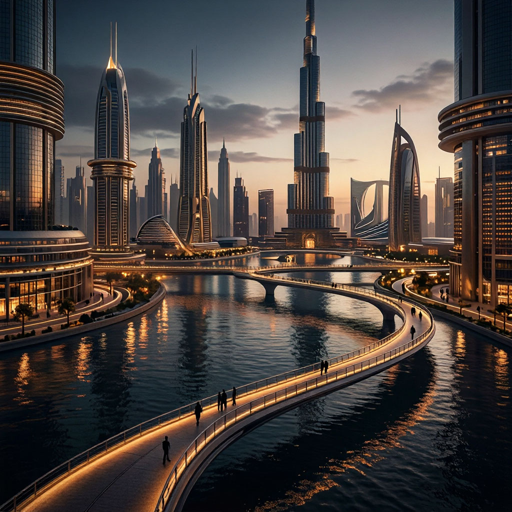

  Инженер SDXL Base 1.0…
Загрузка SDXL: поэтапный перенос CPU → cuda:0…


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

  Намерения sdxl: Создать картину по общей теме


  0%|          | 0/30 [00:00<?, ?it/s]

  SDXL Base 1.0: раунд 1


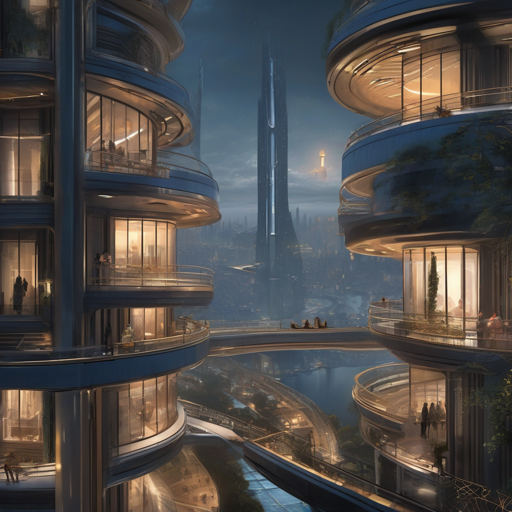

  Qwen разбирает удачные решения, недостатки и оба направления обмена…
  Разбор Yandex ART
    Удачно: Отличная передача освещения и отражений на воде.
    Удачно: Чувство масштаба и кинематографичность.
    Удачно: Плавные линии переднего плана.
    Проблема: Отсутствие спиральных внешних каркасов на башнях.
    Проблема: Передний план больше похож на мост, чем на террасу здания, хотя это допустимо.
  Результат правки: initial — Первый раунд генерации.
    1: pass — Вид с высоты показан через изогнутую конструкцию (террасу/мост) над водой, на фоне виден мегаполис.
    2: pass — На переднем плане видны плавные линии ограждения террасы и силуэты людей, идущих по ней.
    3: fail — Башни вдали колоссальные и со шпилями, но на них отсутствуют спиральные внешние каркасы; они имеют классическую стеклянную или сегментированную структуру.
    4: pass — Между зданиями проходит изогнутый многоуровневый мост/терраса над водой.
    5: pass — Тысячи золотых огней от зданий и террасы ярко отражаютс

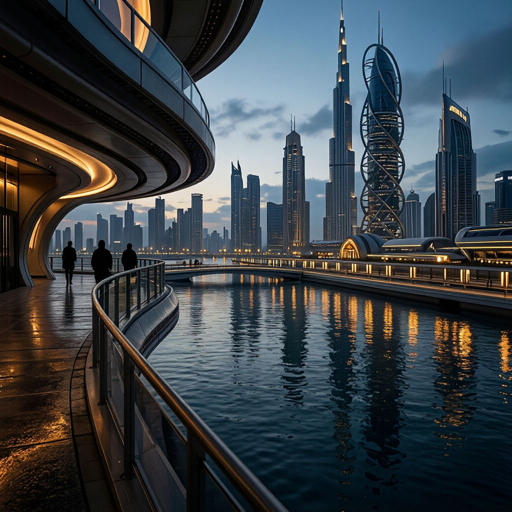

  Инженер SDXL Base 1.0…


Token indices sequence length is longer than the specified maximum sequence length for this model (80 > 77). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (80 > 77). Running this sequence through the model will result in indexing errors


  Намерения sdxl: Добавить спиральные элементы в архитектуру дальних башен.; Усилить освещение дальнего плана и его отражения на воде.; Подчеркнуть, что терраса является частью здания.


  0%|          | 0/30 [00:00<?, ?it/s]

  SDXL Base 1.0: раунд 2


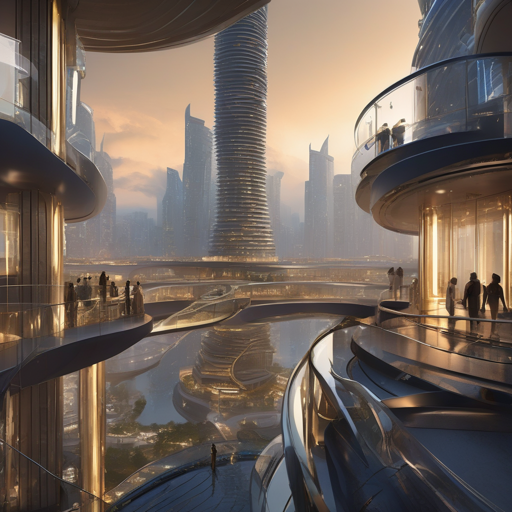

  Qwen разбирает удачные решения, недостатки и оба направления обмена…
  Разбор Yandex ART
    Удачно: Отличная передача масштаба и кинематографичности.
    Удачно: Спиральная башня чётко выделяется и соответствует требованию.
    Удачно: Отражения на воде выглядят реалистично и добавляют глубину.
    Проблема: Терраса на переднем плане всё ещё имеет некоторые черты моста (перильное ограждение), хотя и интегрирована в здание.
    Проблема: Количество отражений можно увеличить для соответствия 'тысячам'.
  Результат правки: realized — Все три запланированные правки выполнены: спиральная башня добавлена, терраса интегрирована в здание, отражения огней яркие и многочисленные.
    1: pass — Вид с изогнутой террасы (передний план) на мегаполис, расположенный над водой (вода занимает нижнюю часть изображения).
    2: pass — Плавные изогнутые линии балкона/террасы на переднем плане и силуэты людей (три фигуры) на террасе.
    3: pass — Вдали видны высокие башни, одна из которых имеет явную сп

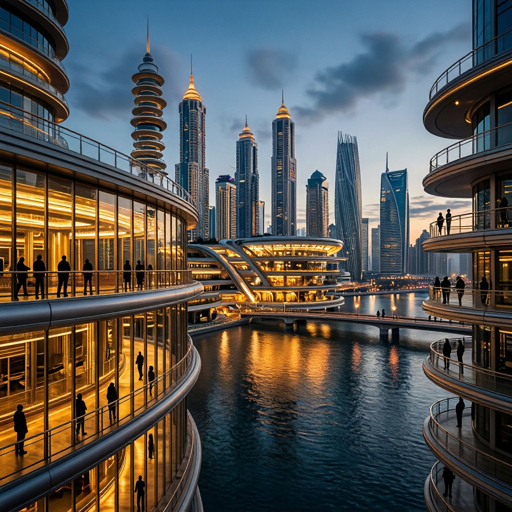

  Инженер SDXL Base 1.0…
  Намерения sdxl: Добавить спиральный элемент к одной из дальних башен.; Усилить освещение дальнего плана и отражения на воде.; Добавить больше деталей к силуэтам людей.
  Перенос: True — Добавить спиральные элементы к башням, как в yandex current.


  0%|          | 0/30 [00:00<?, ?it/s]

  SDXL Base 1.0: раунд 3


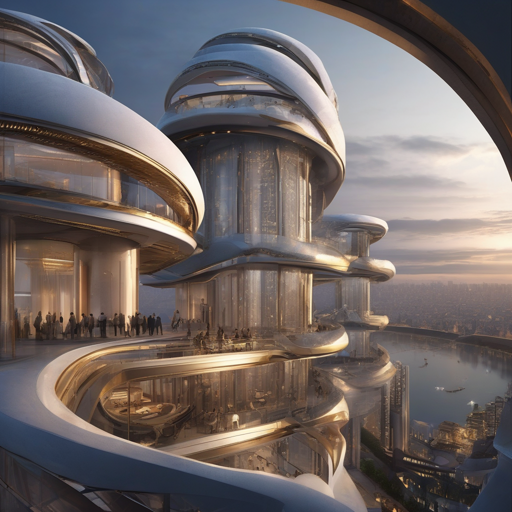

  Qwen разбирает удачные решения, недостатки и оба направления обмена…
  Разбор Yandex ART
    Удачно: Отличная передача атмосферы сумерек и контраста света.
    Удачно: Четкая спиральная структура на одной из башен.
    Проблема: Спиральные элементы присутствуют только на одной башне, на остальных башнях их нет, хотя требовалось 'нескольким'.
  Результат правки: partially_realized — Добавить спиральные элементы к нескольким башням: частично выполнено (только одна башня явно спиральная). Увеличить количество мелких отражений: выполнено. Добавить больше деталей к силуэтам: выполнено.
    1: pass — Вид с высокой изогнутой террасы на гигантский мегаполис над водой передан четко, архитектура доминирует.
    2: pass — Плавные линии балконов присутствуют, силуэты людей видны на разных уровнях и достаточно мелкие.
    3: pass — Башня слева имеет явную спиральную структуру, другие башни имеют шпили.
    4: pass — Вода проходит между зданиями, видны мосты и переходы.
    5: pass — Золотые огни 

/kaggle/working/artist_runs/20261013_195742_7b2e11.zip

Итог Yandex ART · раунд 3


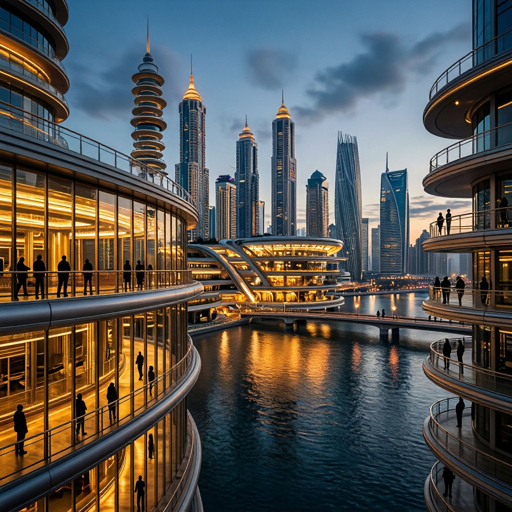

Невыполненные или неясные требования: не обнаружены критиком
Итог SDXL Base 1.0 · раунд 3


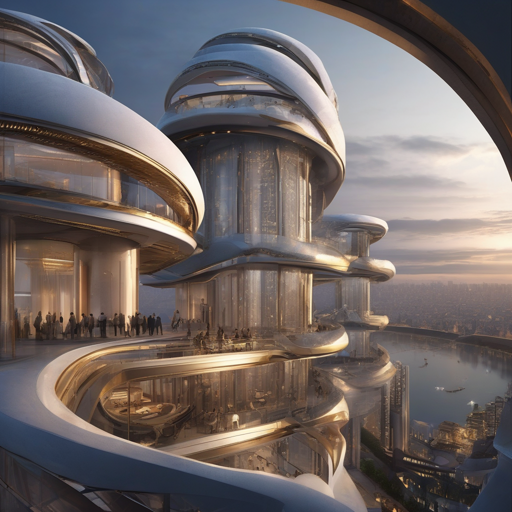

Невыполненные или неясные требования: 3, 5


In [12]:
# ЗАПУСК. Повторное выполнение продолжает тот же эксперимент без лишних генераций.
if RUN_PIPELINE:
    start_session()
    try:
        run_pipeline()
    finally:
        release_memory()
        ARCHIVE_PATH=export_results()
        print('\nАрхив (в том числе незавершённый):',ARCHIVE_PATH)
        display(FileLink(str(ARCHIVE_PATH)))
    show_results()
else:
    print('RUN_PIPELINE=False: API и GPU-модели не запущены.')
